# Houston subsidence, end to end

**Frame F08882 (Houston and the upper Texas Gulf Coast), 2016-10 to
2026-02, 269 granules.** A 30 x 30 km window over northwest Harris County,
where groundwater withdrawal drove subsidence of a few centimeters per year.

The steps of a Cal/Val look at a frame: open and chain, check quality,
reference to a GNSS station, estimate velocities with a robust method, and
compare them with GNSS from the UNR archive.

This notebook ran on real granules; its outputs are saved, and the
documentation build does not run it again.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyproj import Transformer

import disp_xr as dxr

warnings.simplefilter("ignore", FutureWarning)
os.environ["TQDM_DISABLE"] = "1"  # GNSS download progress bars
warnings.filterwarnings("ignore", message="IProgress not found")


def title(ax, text):
    """Title the panel on the left, without xarray's automatic title."""
    ax.set_title("")  # drop xarray's automatic "spatial_ref = 0"
    ax.set_title(text, loc="left")


frame = Path("/u/aurora-r0/govorcin/01_OPERA/DISP/data/F08882")
static_dir = Path("/u/aurora-r0/govorcin/01_OPERA/DISP/data/static/F08882")

raw = dxr.open_disp(
    frame,
    layers=[
        "displacement",
        "temporal_coherence",
        "phase_similarity",
        "recommended_mask",
    ],
)
print(f"{len(raw.attrs['input_granules'])} granules, {dict(raw.sizes)}")

269 granules, {'time': 269, 'y': 7733, 'x': 9464}


## A window over northwest Harris County

Selections are lazy: only the window's chunks are read later.

In [2]:
west, south, east, north = -95.85, 29.75, -95.55, 30.05
to_grid = Transformer.from_crs("EPSG:4326", raw.rio.crs, always_xy=True)
(x0, x1), (y0, y1) = to_grid.transform([west, east], [south, north])
window = raw.sel(x=slice(x0, x1), y=slice(y1, y0))
print(dict(window.sizes))

{'time': 269, 'y': 1086, 'x': 992}


## Quality

The recommended mask varies from epoch to epoch. The quality summary shows
how often each pixel is good, which matters more for a velocity than any
single epoch's mask.

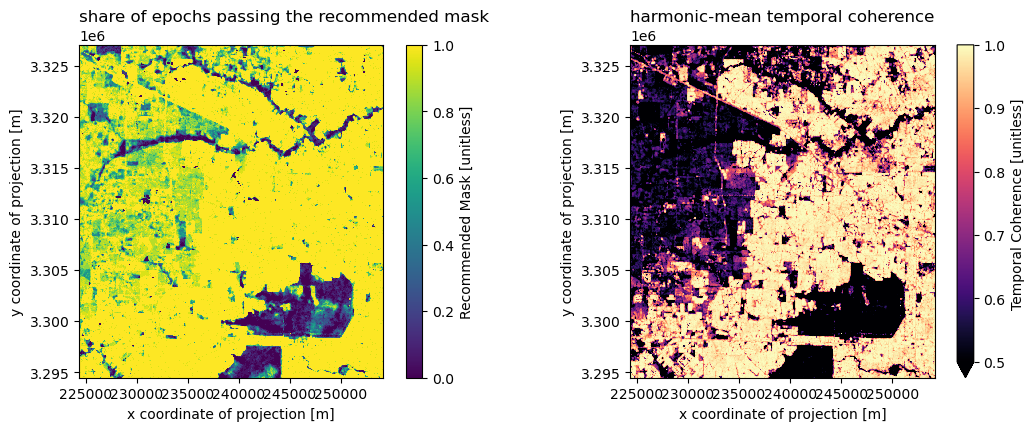

pixels good in at least 90% of epochs: 71%


In [3]:
summary = dxr.quality_summary(window).compute()
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
summary.reliability.plot.imshow(ax=left, vmin=0, vmax=1, cmap="viridis")
title(left, "share of epochs passing the recommended mask")
summary.temporal_coherence_hmean.plot.imshow(ax=right, vmin=0.5, vmax=1, cmap="magma")
title(right, "harmonic-mean temporal coherence")
for ax in (left, right):
    ax.set_aspect("equal")
plt.show()
print(f"pixels good in at least 90% of epochs: {float(summary.reliable.mean()):.0%}")

## Chain and reference to a GNSS station

Mask, chain the ministacks, then reference to the GNSS station nearest the
window center, so DISP and GNSS share a datum.

In [4]:
gps = dxr.gnss.load(window)
center_x, center_y = float(window.x.mean()), float(window.y.mean())
nearest = int(np.hypot(gps.x - center_x, gps.y - center_y).argmin())
station = str(gps.station.values[nearest])
lon, lat = float(gps.lon[nearest]), float(gps.lat[nearest])
print(f"{gps.sizes['station']} UNR stations in the window; reference: {station}")

ds = dxr.stack_disp(dxr.mask(window, "recommended"))
ds = dxr.rereference(
    ds, "area", bbox=(lon - 0.005, lat - 0.005, lon + 0.005, lat + 0.005)
)

13 UNR stations in the window; reference: CFHS


## Velocity

MIDAS is robust to steps and outliers (unwrapping errors, residual
troposphere) and gives a sigma for every pixel. Pixels valid in fewer than
half the epochs are left out: their velocity rests on a handful of dates.

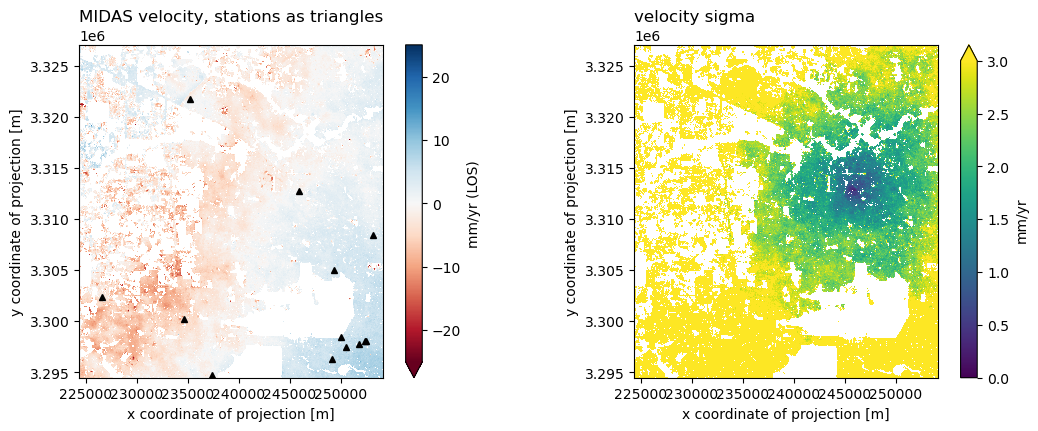

In [5]:
velocity = dxr.fit_velocity(ds, method="midas").compute()
enough = (
    ds.displacement.isel(time=slice(1, None)).notnull().mean("time").compute() >= 0.5
)
vel = 1e3 * velocity.velocity.where(enough)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
vel.plot.imshow(
    ax=left, cmap="RdBu", vmin=-25, vmax=25, cbar_kwargs={"label": "mm/yr (LOS)"}
)
left.plot(gps.x, gps.y, "k^", ms=5)
title(left, "MIDAS velocity, stations as triangles")
(1e3 * velocity.velocity_sigma.where(enough)).plot.imshow(
    ax=right, vmin=0, vmax=3, cbar_kwargs={"label": "mm/yr"}
)
title(right, "velocity sigma")
for ax in (left, right):
    ax.set_aspect("equal")
plt.show()

## Against GNSS

`compare` projects each station's east, north and up onto the line of
sight (from the frame's DISP-S1-STATIC layers), estimates both velocities
with the same method, and scores the OPERA requirements.

DISP is relative to the reference area at the reference station; the GNSS
velocities are in the IGS frame. Every residual therefore carries the same
datum offset, the residual at the reference station itself. The OPERA
velocity requirement is scored on differences between station pairs, where
that offset cancels; the last column removes it explicitly.

In [6]:
static = dxr.open_static(ds, static_dir=static_dir)
result = dxr.residuals.compare(ds, gps, static, buffer_m=60, velocity_method="midas")
table = (
    1e3
    * result.stations[
        ["insar_velocity", "gps_velocity", "velocity_residual", "velocity_sigma"]
    ]
)
offset = table.loc[station, "velocity_residual"]
table["relative_residual"] = table["velocity_residual"] - offset
print(table.round(1).to_string())
relative = table["relative_residual"].drop(station).dropna()
stats = result.summary
print(
    f"\ndatum offset (residual at {station}): {offset:+.1f} mm/yr"
    f"\nRMS of the relative residuals: {np.sqrt((relative**2).mean()):.1f} mm/yr"
    f" over {len(relative)} stations"
    f"\nstation pairs within the velocity requirement:"
    f" {stats['velocity_fraction_passing']:.0%}"
)

      insar_velocity  gps_velocity  velocity_residual  velocity_sigma  relative_residual
ADKS             4.4           6.6               -2.2             4.1               -6.4
AULT             0.2          -3.8                3.9             3.7               -0.3
CFHS             0.3          -3.9                4.2             2.4                0.0
CFJV             3.8          -0.0                3.8             3.5               -0.4
HCC1             5.6           2.9                2.7             4.3               -1.5
HCC2             6.1           2.6                3.5             4.1               -0.7
HPEK            -0.0          -3.6                3.6             4.4               -0.6
KKES             4.2          -1.5                5.7             3.3                1.5
MDWD             6.0           2.8                3.2             4.5               -1.0
MRHK            -3.8           NaN                NaN             NaN                NaN
TXKY            -2.1 

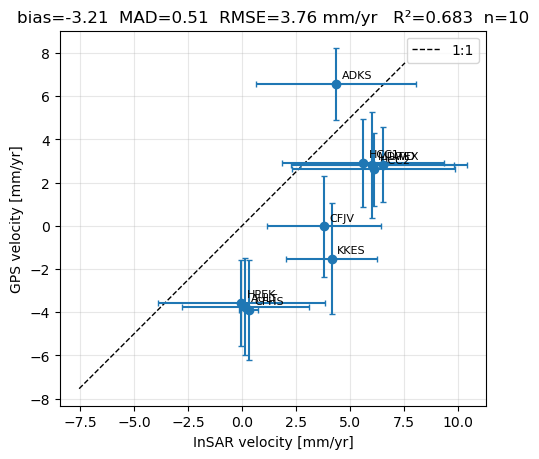

In [7]:
result.plot_velocities(units="mm/yr", scale=1e3)
plt.show()